In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q kagglehub

from google.colab import userdata
import os

os.environ["KAGGLE_API_KEY"] = userdata.get("KAGGLE_API_KEY")

In [32]:
import kagglehub

path = kagglehub.dataset_download(
    "dataclusterlabs/autorickshaw-image-dataset-niche-vehicle-dataset",
    output_dir="/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto"
)

print(path)

100%|██████████| 335M/335M [00:04<00:00, 82.1MB/s]

Extracting files...


/content/drive/MyDrive/Hazard_Detection/raw_datasets/auto


In [4]:
import os
import shutil
import random
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter
import yaml

# ==========================================
# 1. PATHS
# ==========================================

DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

random.seed(42)

# ==========================================
# 2. FIND XML FILES AND MATCH IMAGES
# ==========================================

image_extensions = [".jpg", ".jpeg", ".png"]

annotations = []

for xml_file in DATASET_DIR.rglob("*.xml"):

    try:
        root = ET.parse(xml_file).getroot()

        filename = root.findtext("filename")

        image_path = None

        # First try the filename specified in XML
        if filename:
            candidate = xml_file.parent / Path(filename).name

            if candidate.exists():
                image_path = candidate

        # Fallback: find image with matching stem
        if image_path is None:
            for ext in image_extensions:
                candidate = xml_file.with_suffix(ext)

                if candidate.exists():
                    image_path = candidate
                    break

        if image_path is not None:
            annotations.append((image_path, xml_file))

    except Exception as e:
        print("Invalid XML:", xml_file, e)

print("Matched image-annotation pairs:", len(annotations))

# ==========================================
# 3. EXTRACT ALL CLASS NAMES
# ==========================================

all_classes = set()

for image_path, xml_file in annotations:

    root = ET.parse(xml_file).getroot()

    for obj in root.findall("object"):

        class_name = obj.findtext("name")

        if class_name:
            all_classes.add(class_name.strip())

classes = sorted(all_classes)

class_to_id = {
    name: i for i, name in enumerate(classes)
}

print("\nClasses found:")

for name, class_id in class_to_id.items():
    print(class_id, ":", name)

# ==========================================
# 4. CREATE YOLO FOLDER STRUCTURE
# ==========================================

for split in ["train", "val", "test"]:

    (OUTPUT_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (OUTPUT_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# ==========================================
# 5. SPLIT DATASET
# ==========================================

random.shuffle(annotations)

total = len(annotations)

train_end = int(total * 0.8)
val_end = int(total * 0.9)

splits = {
    "train": annotations[:train_end],
    "val": annotations[train_end:val_end],
    "test": annotations[val_end:]
}

# ==========================================
# 6. CONVERT VOC XML TO YOLO TXT
# ==========================================

image_counts = Counter()
instance_counts = Counter()

from PIL import Image

for split, files in splits.items():

    for image_path, xml_file in files:

        root = ET.parse(xml_file).getroot()

        # Unique filename to avoid collisions
        unique_name = (
            str(image_path.relative_to(DATASET_DIR))
            .replace("\\", "_")
            .replace("/", "_")
        )

        image_name = Path(unique_name).name

        # Copy image
        destination_image = (
            OUTPUT_DIR / "images" / split / image_name
        )

        shutil.copy2(image_path, destination_image)

        # Get actual image dimensions
        with Image.open(image_path) as img:
            img_width, img_height = img.size

        yolo_annotations = []
        image_classes = set()

        for obj in root.findall("object"):

            class_name = obj.findtext("name")

            if not class_name:
                continue

            class_name = class_name.strip()

            bbox = obj.find("bndbox")

            if bbox is None:
                continue

            xmin = float(bbox.findtext("xmin"))
            ymin = float(bbox.findtext("ymin"))
            xmax = float(bbox.findtext("xmax"))
            ymax = float(bbox.findtext("ymax"))

            # Validate bounding box
            if not (
                0 <= xmin < xmax <= img_width
                and 0 <= ymin < ymax <= img_height
            ):
                continue

            # Pascal VOC -> YOLO
            x_center = ((xmin + xmax) / 2) / img_width
            y_center = ((ymin + ymax) / 2) / img_height

            width = (xmax - xmin) / img_width
            height = (ymax - ymin) / img_height

            class_id = class_to_id[class_name]

            yolo_annotations.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

            instance_counts[class_name] += 1
            image_classes.add(class_name)

        # Save YOLO TXT
        label_name = Path(image_name).with_suffix(".txt")

        label_path = (
            OUTPUT_DIR / "labels" / split / label_name
        )

        with open(label_path, "w") as f:
            f.write("\n".join(yolo_annotations))

        for class_name in image_classes:
            image_counts[class_name] += 1

    print(f"{split}: {len(files)} images processed")

# ==========================================
# 7. GENERATE data.yaml
# ==========================================

data_config = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(classes),
    "names": classes
}

with open(OUTPUT_DIR / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

# ==========================================
# 8. DISPLAY STATISTICS
# ==========================================

print("\n========== CONVERSION COMPLETE ==========")

print("Total images:", total)
print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("Testing images:", len(splits["test"]))

print("\nClass statistics:")

for class_name in classes:
    print(
        f"{class_name}: "
        f"{instance_counts[class_name]} instances, "
        f"{image_counts[class_name]} images"
    )

print("\nYOLO dataset saved at:", OUTPUT_DIR)

Matched image-annotation pairs: 100

Classes found:
0 : auto
1 : bicycle
2 : bus
3 : car
4 : concrete_mixer
5 : tempo
6 : tractor
7 : truck_tanker
8 : two_wheelers
9 : vehicle_truck
train: 80 images processed
val: 10 images processed
test: 10 images processed

========== CONVERSION COMPLETE ==========
Total images: 100
Training images: 80
Validation images: 10
Testing images: 10

Class statistics:
auto: 59 instances, 25 images
bicycle: 14 instances, 8 images
bus: 31 instances, 20 images
car: 52 instances, 31 images
concrete_mixer: 9 instances, 9 images
tempo: 13 instances, 10 images
tractor: 19 instances, 14 images
truck_tanker: 10 instances, 10 images
two_wheelers: 82 instances, 34 images
vehicle_truck: 35 instances, 24 images

YOLO dataset saved at: /content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles


In [5]:
print("data.yaml:")
print((OUTPUT_DIR / "data.yaml").read_text())

print("\nSample YOLO annotation:")

label_files = list((OUTPUT_DIR / "labels/train").glob("*.txt"))

if label_files:
    print(label_files[0].read_text())

data.yaml:
path: /content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles
train: images/train
val: images/val
test: images/test
nc: 10
names:
- auto
- bicycle
- bus
- car
- concrete_mixer
- tempo
- tractor
- truck_tanker
- two_wheelers
- vehicle_truck


Sample YOLO annotation:
3 0.649720 0.099972 0.178815 0.087463
3 0.931689 0.104346 0.136621 0.096211
3 0.141187 0.230439 0.282373 0.220117
6 0.374696 0.087579 0.421768 0.161804


In [15]:

from pathlib import Path

LABEL_DIR = Path("/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/labels")

CLASS_MAPPING = {
    0: 3,   # auto -> auto_rickshaw
    1: 1,   # bicycle -> two_wheeler
    2: 4,   # bus -> large_vehicle
    3: 2,   # car -> car
    4: 13,  # concrete_mixer -> obstacle
    5: 3,   # tempo -> auto_rickshaw
    6: 4,   # tractor -> large_vehicle
    7: 4,   # truck_tanker -> large_vehicle
    8: 1,   # two_wheelers -> two_wheeler
    9: 4    # vehicle_truck -> large_vehicle
}
for label_file in LABEL_DIR.glob("*.txt"):

    new_lines = []

    with open(label_file, "r") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()

        if not parts:
            continue

        old_id = int(parts[0])

        if old_id not in CLASS_MAPPING:
            print(f"Unknown class {old_id} in {label_file.name}")
            continue

        new_id = CLASS_MAPPING[old_id]

        parts[0] = str(new_id)

        new_lines.append(" ".join(parts))

    with open(label_file, "w") as f:
        f.write("\n".join(new_lines))

In [10]:
from collections import Counter

class_counts = Counter()

for label_file in LABEL_DIR.glob("*.txt"):
    with open(label_file) as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Remapped class distribution:")

for class_id, count in sorted(class_counts.items()):
    print(class_id, MASTER_CLASSES[class_id], count)

Remapped class distribution:


In [11]:
print("Label directory:", LABEL_DIR)
print("Directory exists:", LABEL_DIR.exists())

label_files = list(LABEL_DIR.glob("*.txt"))

print("Number of TXT files:", len(label_files))
print("First 10 files:", label_files[:10])

Label directory: /content/drive/MyDrive/Hazard_Detection/raw_datasets/vehicle_dataset/labels
Directory exists: False
Number of TXT files: 0
First 10 files: []


In [13]:
from pathlib import Path

LABEL_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/labels"
)

print("Directory exists:", LABEL_DIR.exists())
print("TXT files:", len(list(LABEL_DIR.glob("*.txt"))))

Directory exists: True
TXT files: 0


In [16]:
from collections import Counter

class_counts = Counter()

for label_file in LABEL_DIR.glob("*.txt"):
    with open(label_file) as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Class distribution:")

for class_id, count in sorted(class_counts.items()):
    print(class_id, MASTER_CLASSES[class_id], count)

Class distribution:


In [17]:
from pathlib import Path

LABEL_DIR = Path("/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/labels")

CLASS_MAPPING = {
    0: 3,   # auto -> auto_rickshaw
    1: 1,   # bicycle -> two_wheeler
    2: 4,   # bus -> large_vehicle
    3: 2,   # car -> car
    4: 13,  # concrete_mixer -> obstacle
    5: 3,   # tempo -> auto_rickshaw
    6: 4,   # tractor -> large_vehicle
    7: 4,   # truck_tanker -> large_vehicle
    8: 1,   # two_wheelers -> two_wheeler
    9: 4    # vehicle_truck -> large_vehicle
}
for label_file in LABEL_DIR.glob("*.txt"):

    new_lines = []

    with open(label_file, "r") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()

        if not parts:
            continue

        old_id = int(parts[0])

        if old_id not in CLASS_MAPPING:
            print(f"Unknown class {old_id} in {label_file.name}")
            continue

        new_id = CLASS_MAPPING[old_id]

        parts[0] = str(new_id)

        new_lines.append(" ".join(parts))

    with open(label_file, "w") as f:
        f.write("\n".join(new_lines))

In [18]:
from collections import Counter

class_counts = Counter()

for label_file in LABEL_DIR.glob("*.txt"):
    with open(label_file) as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("Class distribution:")

for class_id, count in sorted(class_counts.items()):
    print(class_id, MASTER_CLASSES[class_id], count)

Class distribution:


In [19]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

print("Base directory exists:", BASE_DIR.exists())

for path in BASE_DIR.rglob("*"):
    if path.is_file():
        print(path)

Base directory exists: True
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/data.yaml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/Indian_vehicle_dataset/20210427_05_35_43_000_ovRKxW0QbBVfwN9RW4teROP1YgG3_F_4160_3120.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/Indian_vehicle_dataset/20210427_05_35_43_000_ovRKxW0QbBVfwN9RW4teROP1YgG3_F_4160_3120.xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/Indian_vehicle_dataset/20210427_07_32_15_000_T4CaxysrQ7W21Wgl1wZWBCtdRjE3_F_3264_2448.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/Indian_vehicle_dataset/20210427_07_32_15_000_T4CaxysrQ7W21Wgl1wZWBCtdRjE3_F_3264_2448.xml
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/Indian_vehicle_dataset/20210427_22_52_25_000_Db2I2d17GLf53JzlQRSP28hD4Ml1_F_2592_1944.jpg
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/Indian_vehicle_dataset/202104

In [20]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

for split in ["train", "valid", "test"]:
    image_dir = BASE_DIR / "images" / split
    label_dir = BASE_DIR / "labels" / split

    print(f"\n{split.upper()}")
    print("Images:", len(list(image_dir.glob("*"))) if image_dir.exists() else "Missing")
    print("Labels:", len(list(label_dir.glob("*.txt"))) if label_dir.exists() else "Missing")


TRAIN
Images: 80
Labels: 80

VALID
Images: Missing
Labels: Missing

TEST
Images: 10
Labels: 10


In [21]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

REMAP_DIR = BASE_DIR / "remapped"

for split in ["train", "test"]:
    (REMAP_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

print("Remapped directories created!")

Remapped directories created!


In [23]:
CLASS_MAPPING = {
    0: 3,    # auto -> auto_rickshaw
    1: 1,    # bicycle -> two_wheeler
    2: 4,    # bus -> large_vehicle
    3: 2,    # car -> car
    4: 13,   # concrete_mixer -> obstacle
    5: 3,    # tempo -> auto_rickshaw (verify this)
    6: 4,    # tractor -> large_vehicle
    7: 4,    # truck_tanker -> large_vehicle
    8: 1,    # two_wheelers -> two_wheeler
    9: 4     # vehicle_truck -> large_vehicle
}

for split in ["train", "test"]:

    original_label_dir = BASE_DIR / "labels" / split
    output_label_dir = REMAP_DIR / "labels" / split

    for label_file in original_label_dir.glob("*.txt"):

        new_lines = []

        with open(label_file, "r") as f:
            for line in f:

                parts = line.strip().split()

                if not parts:
                    continue

                old_id = int(parts[0])

                if old_id not in CLASS_MAPPING:
                    raise ValueError(
                        f"Unknown class ID {old_id} in {label_file}"
                    )

                parts[0] = str(CLASS_MAPPING[old_id])
                new_lines.append(" ".join(parts))

        output_file = output_label_dir / label_file.name

        with open(output_file, "w") as f:
            f.write("\n".join(new_lines))

print("All annotations remapped successfully!")

All annotations remapped successfully!


In [24]:
from collections import Counter

MASTER_CLASSES = {
    0: "person",
    1: "two_wheeler",
    2: "car",
    3: "auto_rickshaw",
    4: "large_vehicle",
    5: "large_animal",
    6: "dog",
    7: "pothole",
    8: "open_drain",
    9: "speed_breaker",
    10: "stairs_up",
    11: "stairs_down",
    12: "curb_or_step",
    13: "obstacle",
    14: "vendor_stall",
    15: "bench",
    16: "chair",
    17: "door",
    18: "sports_balls",
    19: "traffic_lights",
    20: "other_hazards"
}

class_counts = Counter()

for label_file in (REMAP_DIR / "labels").rglob("*.txt"):
    with open(label_file) as f:
        for line in f:
            if line.strip():
                class_counts[int(line.split()[0])] += 1

print("RE-MAPPED CLASS DISTRIBUTION\n")

for class_id, class_name in MASTER_CLASSES.items():
    print(f"{class_id:2} | {class_name:18} | {class_counts[class_id]}")

RE-MAPPED CLASS DISTRIBUTION

 0 | person             | 0
 1 | two_wheeler        | 84
 2 | car                | 43
 3 | auto_rickshaw      | 60
 4 | large_vehicle      | 79
 5 | large_animal       | 0
 6 | dog                | 0
 7 | pothole            | 0
 8 | open_drain         | 0
 9 | speed_breaker      | 0
10 | stairs_up          | 0
11 | stairs_down        | 0
12 | curb_or_step       | 0
13 | obstacle           | 9
14 | vendor_stall       | 0
15 | bench              | 0
16 | chair              | 0
17 | door               | 0
18 | sports_balls       | 0
19 | traffic_lights     | 0
20 | other_hazards      | 0


In [25]:
from pathlib import Path
import shutil
import random

BASE_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles"
)

FINAL_DIR = BASE_DIR / "YOLO"

if FINAL_DIR.exists():
    raise FileExistsError(
        "YOLO folder already exists. Check it before running again."
    )

# Create final directories
for split in ["train", "valid", "test"]:
    (FINAL_DIR / "images" / split).mkdir(parents=True)
    (FINAL_DIR / "labels" / split).mkdir(parents=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Check and move original images + remapped annotations
for split in ["train", "test"]:

    image_dir = BASE_DIR / "images" / split
    label_dir = BASE_DIR / "remapped" / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    if image_stems != label_stems:
        raise ValueError(
            f"Image-label mismatch in {split}!\n"
            f"Missing labels: {image_stems - label_stems}\n"
            f"Missing images: {label_stems - image_stems}"
        )

    for image in images:
        shutil.move(
            str(image),
            str(FINAL_DIR / "images" / split / image.name)
        )

    for label in labels:
        shutil.move(
            str(label),
            str(FINAL_DIR / "labels" / split / label.name)
        )

print("Images and remapped labels moved successfully!")

Images and remapped labels moved successfully!


In [26]:
import random
import shutil

random.seed(42)

train_images = list(
    (FINAL_DIR / "images" / "train").iterdir()
)

valid_count = round(len(train_images) * 0.20)

valid_images = random.sample(train_images, valid_count)

for image in valid_images:

    label = FINAL_DIR / "labels" / "train" / f"{image.stem}.txt"

    shutil.move(
        str(image),
        str(FINAL_DIR / "images" / "valid" / image.name)
    )

    shutil.move(
        str(label),
        str(FINAL_DIR / "labels" / "valid" / label.name)
    )

print("Validation split created!")
print("Training:", len(list((FINAL_DIR / "images/train").iterdir())))
print("Validation:", len(list((FINAL_DIR / "images/valid").iterdir())))
print("Testing:", len(list((FINAL_DIR / "images/test").iterdir())))

Validation split created!
Training: 64
Validation: 16
Testing: 10


In [27]:
import yaml

MASTER_CLASSES = [
    "person",
    "two_wheeler",
    "car",
    "auto_rickshaw",
    "large_vehicle",
    "large_animal",
    "dog",
    "pothole",
    "open_drain",
    "speed_breaker",
    "stairs_up",
    "stairs_down",
    "curb_or_step",
    "obstacle",
    "vendor_stall",
    "bench",
    "chair",
    "door",
    "sports_balls",
    "traffic_lights",
    "other_hazards"
]

data = {
    "path": str(FINAL_DIR),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(MASTER_CLASSES),
    "names": MASTER_CLASSES
}

yaml_path = FINAL_DIR / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("data.yaml created!")
print(yaml_path)

with open(yaml_path) as f:
    print(f.read())

data.yaml created!
/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/YOLO/data.yaml
path: /content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/YOLO
train: images/train
val: images/valid
test: images/test
nc: 21
names:
- person
- two_wheeler
- car
- auto_rickshaw
- large_vehicle
- large_animal
- dog
- pothole
- open_drain
- speed_breaker
- stairs_up
- stairs_down
- curb_or_step
- obstacle
- vendor_stall
- bench
- chair
- door
- sports_balls
- traffic_lights
- other_hazards



In [28]:
for split in ["train", "valid", "test"]:

    img_dir = FINAL_DIR / "images" / split
    lbl_dir = FINAL_DIR / "labels" / split

    images = {
        p.stem for p in img_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    }

    labels = {p.stem for p in lbl_dir.glob("*.txt")}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Matched:", images == labels)


TRAIN
Images: 64
Labels: 64
Matched: True

VALID
Images: 16
Labels: 16
Matched: True

TEST
Images: 10
Labels: 10
Matched: True


In [29]:
# Delete original annotations
original_labels = BASE_DIR / "labels"

if original_labels.exists():
    shutil.rmtree(original_labels)

# Delete intermediate remapped folder
remapped_dir = BASE_DIR / "remapped"

if remapped_dir.exists():
    shutil.rmtree(remapped_dir)

# Remove now-empty original image directories
for split in ["train", "test"]:
    old_dir = BASE_DIR / "images" / split

    if old_dir.exists() and not any(old_dir.iterdir()):
        old_dir.rmdir()

print("Redundant folders removed!")

Redundant folders removed!


Total annotations: 275
Total classes: 5


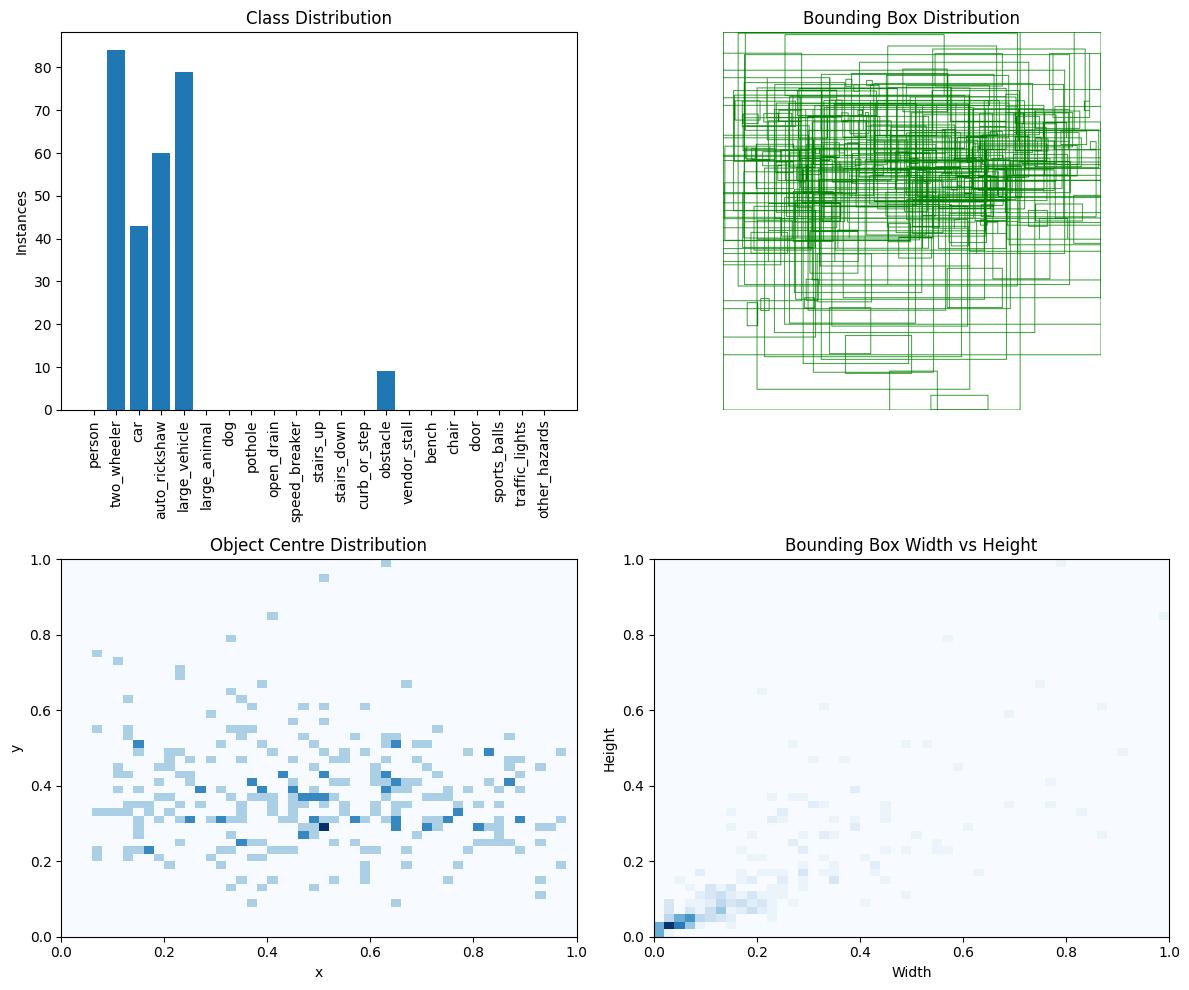

Saved analysis to: /content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/YOLO/dataset_analysis.jpg


In [30]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import ImageDraw, Image

# Dataset location
DATASET_DIR = Path(
    "/content/drive/MyDrive/Hazard_Detection/raw_datasets/indian_vehicles/YOLO"
)

# Read data.yaml
yaml_path = DATASET_DIR / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

names = config["names"]

if isinstance(names, list):
    names = dict(enumerate(names))

# Find label directories using the dataset splits
base = Path(config.get("path", DATASET_DIR))

if not base.is_absolute():
    base = (yaml_path.parent / base).resolve()

label_dirs = set()

for split in ["train", "val", "valid", "test"]:
    split_path = config.get(split)

    if not split_path:
        continue

    paths = split_path if isinstance(split_path, list) else [split_path]

    for p in paths:
        p = Path(p)

        if not p.is_absolute():
            p = (base / p).resolve()

        parts = list(p.parts)

        if "images" in parts:
            parts[parts.index("images")] = "labels"
            label_dirs.add(Path(*parts))
        else:
            print("Check label folder for:", p)

# Read annotations
classes = []
boxes = []

for label_dir in label_dirs:
    if not label_dir.exists():
        print("Missing:", label_dir)
        continue

    for file in label_dir.rglob("*.txt"):
        with open(file, "r") as f:
            for line in f:
                values = line.strip().split()

                if len(values) < 5:
                    continue

                cls, x, y, w, h = map(float, values[:5])

                classes.append(int(cls))
                boxes.append([x, y, w, h])

classes = np.array(classes)
boxes = np.array(boxes)

print("Total annotations:", len(classes))
print("Total classes:", len(set(classes)))

# Class distribution
counts = np.bincount(
    classes.astype(int),
    minlength=len(names)
)

# Generate plots
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Class distribution
ax[0, 0].bar(range(len(names)), counts)

ax[0, 0].set_xticks(range(len(names)))
ax[0, 0].set_xticklabels(
    [names[i] for i in range(len(names))],
    rotation=90
)

ax[0, 0].set_ylabel("Instances")
ax[0, 0].set_title("Class Distribution")

# 2. Bounding box visualization
img = Image.new("RGB", (1000, 1000), "white")
draw = ImageDraw.Draw(img)

for x, y, w, h in boxes[:500]:
    x1 = (x - w/2) * 1000
    y1 = (y - h/2) * 1000
    x2 = (x + w/2) * 1000
    y2 = (y + h/2) * 1000

    draw.rectangle([x1, y1, x2, y2], outline="green", width=2)

ax[0, 1].imshow(img)
ax[0, 1].set_title("Bounding Box Distribution")
ax[0, 1].axis("off")

# 3. Object centre distribution
ax[1, 0].hist2d(
    boxes[:, 0],
    boxes[:, 1],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 0].set_xlabel("x")
ax[1, 0].set_ylabel("y")
ax[1, 0].set_title("Object Centre Distribution")

# 4. Width-height distribution
ax[1, 1].hist2d(
    boxes[:, 2],
    boxes[:, 3],
    bins=50,
    range=[[0, 1], [0, 1]],
    cmap="Blues"
)

ax[1, 1].set_xlabel("Width")
ax[1, 1].set_ylabel("Height")
ax[1, 1].set_title("Bounding Box Width vs Height")

plt.tight_layout()

# Save results
output_path = DATASET_DIR / "dataset_analysis.jpg"

plt.savefig(output_path, dpi=200)
plt.show()

print("Saved analysis to:", output_path)